# DuckDB, pandas, and Matplotlib Analysis
Use SQL to analyze `employees.csv`, then make charts with pandas and Matplotlib. Run cells from top to bottom. This notebook uses a temporary DuckDB database.

## Contents
1. Libraries and Data Source
2. Connect to DuckDB
3. Read CSV Data and Convert to pandas
4. Create Tables
5. Sort, Filter, and Aggregate
6. Bonuses and Calculated Columns
7. Group Salaries by Team and Gender
8. Cast Data Types
9. Visualize Results and Manage Tables
10. Practice

## 1. Libraries and Data Source
DuckDB runs SQL on your data. pandas stores the results, and Matplotlib makes charts. Install the packages if needed:

```python
%pip install duckdb pandas matplotlib
```

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('employees.csv')
if not csv_path.is_file():
    raise FileNotFoundError('Place employees.csv beside this notebook before continuing.')
print('Data source:', csv_path.name)

Data source: employees.csv


### Downloading the Dataset with KaggleHub
`employees.csv` is included in this repo. To download a fresh copy from Kaggle, install `kagglehub` and run the code below. Existing CSV files are kept.

```python
%pip install kagglehub

import kagglehub
import shutil

download_path = Path(kagglehub.dataset_download('prakharjadaun/employee-data'))
print([file.name for file in download_path.iterdir()])
for source_file in download_path.glob('*.csv'):
    destination = Path.cwd() / source_file.name
    if not destination.exists():
        shutil.copy2(source_file, destination)
```

## 2. Connect to DuckDB
`duckdb.connect()` opens a temporary database. Closing the connection removes its tables. To keep tables between sessions, connect to a file: `duckdb.connect('employees_learning.duckdb')`. Use `conn` for all queries below.

In [2]:
conn = duckdb.connect()
print(conn.execute('SELECT 42').fetchall())

[(42,)]


## 3. Read CSV Data and Convert to pandas
Read the CSV with `conn.read_csv()`. This gives a relation: a table-like result you can query. Use `.df()` to turn it into a pandas DataFrame.

In [3]:
employees_rel = conn.read_csv(str(csv_path), header=True)
print('Columns:', employees_rel.columns)
print('Types:', employees_rel.types)
print(employees_rel)

Columns: ['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary', 'Bonus %', 'Senior Management', 'Team']
Types: [VARCHAR, VARCHAR, DATE, VARCHAR, BIGINT, DOUBLE, BOOLEAN, VARCHAR]
┌────────────┬─────────┬────────────┬─────────────────┬────────┬─────────┬───────────────────┬──────────────────────┐
│ First Name │ Gender  │ Start Date │ Last Login Time │ Salary │ Bonus % │ Senior Management │         Team         │
│  varchar   │ varchar │    date    │     varchar     │ int64  │ double  │      boolean      │       varchar        │
├────────────┼─────────┼────────────┼─────────────────┼────────┼─────────┼───────────────────┼──────────────────────┤
│ Douglas    │ Male    │ 1993-08-06 │ 12:42 PM        │  97308 │   6.945 │ true              │ Marketing            │
│ Thomas     │ Male    │ 1996-03-31 │ 6:53 AM         │  61933 │    4.17 │ true              │ NULL                 │
│ Maria      │ Female  │ 1993-04-23 │ 11:17 AM        │ 130590 │  11.858 │ false             │ Finan

In [4]:
employees_df = employees_rel.df()
print(f'Loaded {len(employees_df):,} rows and {len(employees_df.columns)} columns.')
employees_df.head()

Loaded 1,000 rows and 8 columns.


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,1993-08-06,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,1996-03-31,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,1993-04-23,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,2005-03-04,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1998-01-24,4:47 PM,101004,1.389,True,Client Services


## 4. Create Tables
### Create a table from the existing relation
`create()` saves the relation as a table. Drop the old table first so you can rerun the cell. Your CSV stays unchanged.

In [5]:
conn.execute('DROP TABLE IF EXISTS employees')
employees_rel.create('employees')
conn.sql('SELECT COUNT(*) AS total_rows FROM employees').df()

,total_rows
0,1000


### Alternative: create the table directly from CSV
This is another way to create the same table. Choose this method or the one above; you only need one.

```python
conn.execute(
    "CREATE OR REPLACE TABLE employees AS SELECT * FROM read_csv_auto(?)",
    [str(csv_path)],
)
```

## 5. Sort, Filter, and Aggregate
`ORDER BY Salary DESC` sorts salaries from highest to lowest. `LIMIT` shows fewer rows. Use `.df()` for a DataFrame or `.fetchall()` for a list of tuples. `AVG()` skips missing values.

In [6]:
conn.sql('SELECT * FROM employees ORDER BY Salary DESC LIMIT 10').df()

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Katherine,Female,1996-08-13,12:21 AM,149908,18.912,False,Finance
1,Rose,Female,2015-05-28,8:40 AM,149903,5.630,False,Human Resources
2,Cynthia,Female,2006-07-12,8:55 AM,149684,7.864,False,Product
3,NaN,Female,2005-02-23,9:50 PM,149654,1.825,<NA>,Sales
4,Kathy,Female,2000-03-18,7:26 PM,149563,16.991,True,Finance
5,Russell,NaN,2009-05-09,11:59 AM,149456,3.533,False,Marketing
6,Andrea,Female,1999-07-22,9:25 AM,149105,13.707,True,Distribution
7,James,Male,1993-01-15,5:19 PM,148985,19.280,False,Legal
8,Clarence,Male,1989-08-05,6:11 PM,148941,11.517,False,Product
9,Maria,NaN,1985-06-19,1:48 AM,148857,8.738,False,Legal


In [7]:
average_salary = conn.execute('SELECT AVG(Salary) AS average_salary FROM employees').fetchall()
print(average_salary)

[(90662.181,)]


### Parameterized filtering
Use `?` to pass a value from Python into SQL. Use double quotes for column names and single quotes for text values. Parameters are for values, not table or column names.

In [8]:
minimum_salary = 100_000
conn.execute('SELECT * FROM employees WHERE Salary >= ? ORDER BY Salary DESC LIMIT 10', [minimum_salary]).df()

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Katherine,Female,1996-08-13,12:21 AM,149908,18.912,False,Finance
1,Rose,Female,2015-05-28,8:40 AM,149903,5.630,False,Human Resources
2,Cynthia,Female,2006-07-12,8:55 AM,149684,7.864,False,Product
3,NaN,Female,2005-02-23,9:50 PM,149654,1.825,<NA>,Sales
4,Kathy,Female,2000-03-18,7:26 PM,149563,16.991,True,Finance
5,Russell,NaN,2009-05-09,11:59 AM,149456,3.533,False,Marketing
6,Andrea,Female,1999-07-22,9:25 AM,149105,13.707,True,Distribution
7,James,Male,1993-01-15,5:19 PM,148985,19.280,False,Legal
8,Clarence,Male,1989-08-05,6:11 PM,148941,11.517,False,Product
9,Maria,NaN,1985-06-19,1:48 AM,148857,8.738,False,Legal


## 6. Bonuses and Calculated Columns
Put column names with spaces or symbols in double quotes, like `"Bonus %"`. The query below finds everyone with the highest bonus.

In [9]:
conn.sql('SELECT MAX("Bonus %") AS highest_bonus_percent FROM employees').df()

,highest_bonus_percent
0,19.944


In [10]:
conn.sql("""
    SELECT *
    FROM employees
    WHERE "Bonus %" = (SELECT MAX("Bonus %") FROM employees)
""").df()

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Robert,Male,2007-03-11,11:20 AM,135882,19.944,False,Legal


### Calculate total compensation
Total pay is salary plus bonus. Divide the bonus percentage by `100` before multiplying. This query adds a result column; it does not change the table. Missing salary or bonus values give a missing total.

In [11]:
compensation_df = conn.sql("""
    SELECT "First Name", Team, Salary, "Bonus %",
           Salary + (Salary * "Bonus %" / 100.0) AS Total
    FROM employees
    ORDER BY Total DESC NULLS LAST
""").df()
compensation_df.head(10)

,First Name,Team,Salary,Bonus %,Total
0,Katherine,Finance,149908,18.912,178258.60096
1,James,Legal,148985,19.280,177709.30800
2,Kathy,Finance,149563,16.991,174975.24933
3,Rose,Engineering,145001,19.850,173783.69850
4,Marie,Human Resources,145988,18.685,173265.85780
5,Jacqueline,Marketing,145988,18.243,172620.59084
6,NaN,Human Resources,145316,18.517,172224.16372
7,Bobby,NaN,147842,16.158,171730.31036
8,Shirley,Legal,147113,16.135,170849.68255
9,Jane,Product,144474,17.648,169970.77152


## 7. Group Salaries by Team and Gender
`GROUP BY` summarizes each team or gender. These examples skip missing group names. `COUNT(*)` counts rows; `COUNT(Salary)` counts recorded salaries.

In [12]:
team_summary = conn.sql('''
    SELECT Team, COUNT(*) AS employee_count,
           COUNT(Salary) AS salary_count,
           AVG(Salary) AS average_salary, MAX(Salary) AS highest_salary
    FROM employees
    WHERE Team IS NOT NULL
    GROUP BY Team
    ORDER BY average_salary DESC
''').df()
team_summary

,Team,employee_count,salary_count,average_salary,highest_salary
0,Engineering,92,92,94269.195652,147362
1,Finance,102,102,92219.480392,149908
2,Sales,94,94,92173.436170,149654
3,Business Development,101,101,91866.316832,147417
4,Human Resources,91,91,90944.527473,149903
5,Marketing,98,98,90435.591837,149456
6,Legal,88,88,89303.613636,148985
7,Product,95,95,88665.505263,149684
8,Distribution,90,90,88500.466667,149105
9,Client Services,106,106,88224.424528,147183


In [13]:
gender_summary = conn.sql('''
    SELECT Gender, COUNT(*) AS employee_count,
           AVG(Salary) AS average_salary, MAX(Salary) AS highest_salary
    FROM employees
    WHERE Gender IS NOT NULL
    GROUP BY Gender
    ORDER BY Gender
''').df()
gender_summary

,Gender,employee_count,average_salary,highest_salary
0,Female,431,90023.923434,149908
1,Male,424,91180.669811,148985


## 8. Cast Data Types
Casting changes a value’s type. Use `CAST(value AS type)` or `value::type`. `DOUBLE` stores decimal numbers. Casting to an integer removes decimal precision, so keep the original bonus for pay calculations.

In [14]:
conn.sql('SELECT Salary, Salary::DOUBLE AS salary_decimal FROM employees LIMIT 5').df()

,Salary,salary_decimal
0,97308,97308.0
1,61933,61933.0
2,130590,130590.0
3,138705,138705.0
4,101004,101004.0


In [15]:
conn.sql('SELECT "Bonus %", CAST("Bonus %" AS INTEGER) AS bonus_integer FROM employees LIMIT 5').df()

,Bonus %,bonus_integer
0,6.945,7
1,4.170,4
2,11.858,12
3,9.340,9
4,1.389,1


### Handling invalid text
`CAST()` fails on invalid text. `TRY_CAST()` returns `NULL` instead, shown as a missing value in pandas.

In [16]:
conn.sql("SELECT raw_value, TRY_CAST(raw_value AS DOUBLE) AS numeric_value FROM (VALUES ('125.5'), ('unknown')) AS sample(raw_value)").df()

,raw_value,numeric_value
0,125.5,125.5
1,unknown,NaN


## 9. Visualize Results and Manage Tables
### Plot a SQL summary
SQL calculates the summary. pandas holds it, and Matplotlib turns it into a chart. Sort the values to make comparisons easier.

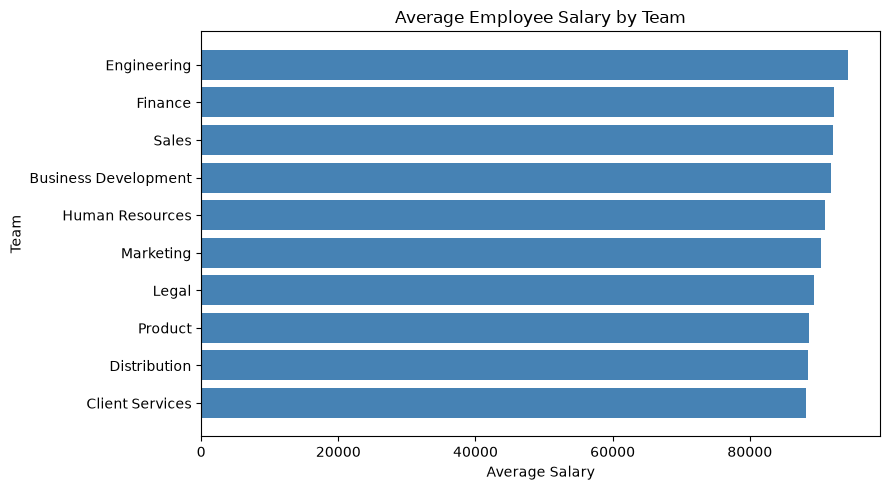

In [17]:
plot_data = team_summary.sort_values('average_salary')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data['Team'], plot_data['average_salary'], color='steelblue')
ax.set(title='Average Employee Salary by Team', xlabel='Average Salary', ylabel='Team')
fig.tight_layout()
plt.show()

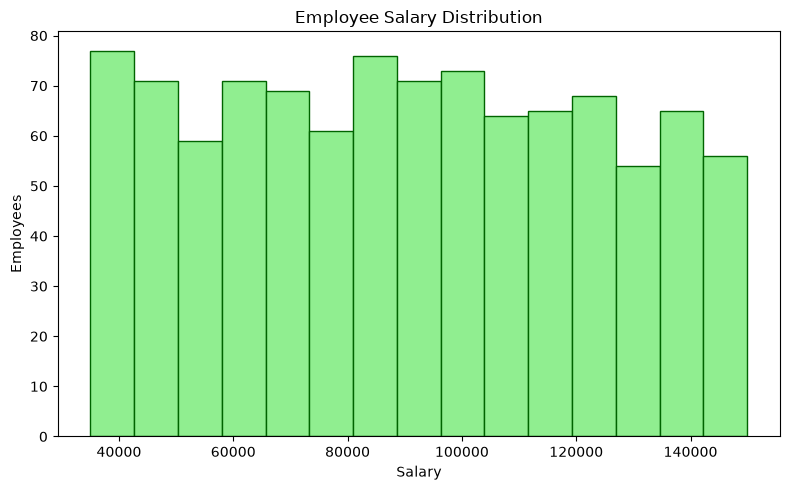

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(employees_df['Salary'].dropna(), bins=15, color='lightgreen', edgecolor='darkgreen')
ax.set(title='Employee Salary Distribution', xlabel='Salary', ylabel='Employees')
fig.tight_layout()
plt.show()

### List and remove tables
`SHOW TABLES` lists your tables. `DROP TABLE` removes the temporary table. The CSV and pandas DataFrames stay available.

In [19]:
display(conn.sql('SHOW TABLES').df())
conn.execute('DROP TABLE IF EXISTS employees')
display(conn.sql('SHOW TABLES').df())

,name
0,employees


,name


### Optional exports and closing
Remove `#` from an export line to save a CSV or chart. `conn.close()` closes the database. To query again, rerun from section 2.

In [20]:
# team_summary.to_csv('duckdb_team_summary.csv', index=False)
# fig.savefig('duckdb_salary_distribution.png', dpi=150, bbox_inches='tight')

conn.close()
print('DuckDB connection closed.')

DuckDB connection closed.


## 10. Practice
1. Reconnect and recreate the employees table.
2. Compare the relation preview with the pandas DataFrame.
3. Try the direct CSV method instead of the relation-based table creation.
4. Find the five highest salaries.
5. Filter salaries using a parameter supplied by Python.
6. Return every employee tied for the highest bonus.
7. Calculate total compensation without altering the source table.
8. Compare average salaries by team and gender.
9. Try `CAST()` and `TRY_CAST()` on valid and invalid values.
10. Plot a grouped result, inspect the tables, and close the connection.

In [21]:
# Write your practice code here
